# 08 · Fatigue-aware day-ahead warning policy (H5)

**H5.** A fatigue-constrained warning policy catches more unhealthy days per alert than a single-threshold rule on the test winter.

**Why fatigue matters.** People respond less to repeated alerts: avoidance behaviour fades after one or two consecutive alert days (Graff Zivin & Neidell 2009). So the policy caps consecutive level-2 warnings (the next day is downgraded to an advisory) and limits level-2 warnings to 20 days per winter.

**Why a single official-line alert fails here.** The national 24-hour line (MNS 4585:2025, 37.5 µg/m³) is exceeded on about 89% of training smog-season days, so an alert on that line would sound almost every winter day.

**Policy.** Level 2 (warning) if the forecast ≥ t2, level 1 (advisory) if t1 ≤ forecast < t2. The input forecast, t1 and t2 are chosen on the two validation winters (2021/22, 2023/24) by severity-weighted recall within per-winter budgets (at most 20 warning days and at most 40 alert days of any level), ties to fewer alerts; all rules are in config `warnings`. The test winter is sealed until 23 November.

**Revision (validation finding).** The first version (tag `pre-test`) budgeted warnings only. Advisories were free, so the search drove the advisory threshold to the grid floor (80 µg/m³) and alerted on 158 of 219 validation days. The total alert budget was added after that validation run, before any test data was seen (tag `pre-test-v2`).

All logic lives in `src/uaq/warnings.py`; this notebook only calls it.

In [1]:
# Setup: works whether or not you ran `pip install -e .`
import sys, pathlib, json
sys.path.insert(0, str(pathlib.Path.cwd().resolve().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from IPython.display import display, Markdown

from uaq.config import load_config, ROOT
from uaq import models
from uaq import warnings as wp
from uaq.periods import season_label, season_year
cfg = load_config()
W = cfg["warnings"]
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
%matplotlib inline
print("Project root:", ROOT)

Project root: /Users/user/Desktop/neural


## 1 · Inputs and validation days
Forecasts from notebooks 05 (MLP, boosting) and 06 (LSTM), validation folds only; today's value (`pm_lag0`) from the feature table. Every input is scored on the same days: every validation smog-season day with an observed value. A day where an input has no forecast gets no alert.

In [2]:
res_dir = ROOT / "outputs" / "results"
feat = pd.read_csv(ROOT / "data" / "processed" / "features_8160.csv", parse_dates=["date", "target_date"])
nb05 = pd.read_csv(res_dir / "forecast_val_predictions.csv", parse_dates=["target_date"])
nb06 = pd.read_csv(res_dir / "lstm_val_predictions.csv", parse_dates=["target_date"])
preds = nb05.merge(nb06.drop(columns="y"), on=["target_date", "fold"], how="outer").set_index("target_date")

thr_name, thr, thr_why = models.event_threshold(feat, cfg)
assert abs(thr - W["high"]) < 1e-9, "warnings.high must equal the notebook 05 threshold"
print(f"high = {W['high']} µg/m³ ({thr_name}). {thr_why}")
very_high = wp.very_high_value(feat, cfg)
print(f"very high = {very_high:.1f} µg/m³ (training smog-season {W['very_high_quantile']:.0%} percentile)")

y = wp.validation_days(feat, cfg)
inputs = {n: wp.input_series(n, preds, feat) for n in W["inputs"]}
winter = pd.Series([season_label(int(s)) for s in season_year(pd.Series(y.index))], index=y.index)
tab = pd.DataFrame({"days with observed y": y.groupby(winter).size(),
                    "high days": (y > W["high"]).groupby(winter).sum(),
                    "very-high days": (y > very_high).groupby(winter).sum()})
for n, f in inputs.items():
    tab[f"forecast: {n}"] = f.reindex(y.index).notna().groupby(winter).sum()
display(tab.T)

high = 170.8 µg/m³ (train_p75). Every official threshold is exceeded too often in training (mns_4585_2025 89%, mns_4585_2016 81%, who_it1_2021 66%), so a study-defined training percentile is used. Report the official rates as context.
very high = 221.4 µg/m³ (training smog-season 90% percentile)


,2021/22,2023/24
days with observed y,111,108
high days,33,22
very-high days,16,5
forecast: mlp (weather),102,101
forecast: lstm (weather),90,87
forecast: hgb (weather),102,101
"forecast: max(mlp, today)",102,101
"forecast: max(lstm, today)",90,87


## 2 · Search on validation
Every input × (t1 < t2) on the 80–400 µg/m³ grid (step 10); keep combinations with at most 20 level-2 days **and** at most 40 alert days of any level in **each** validation winter; maximise severity-weighted recall (a high day earns 1 if alerted at any level; a very-high day earns 2 at level 2, 1 at level 1); ties go to fewer alerts.

*Revision:* the 40-alert-day budget (all levels) was added after the first validation run, because with advisories unbudgeted the search set t1 to the grid floor (80) and alerted on 158 of 219 days (0.34 caught per alert vs 0.59 for the single-threshold rule).

In [3]:
res = wp.search(inputs, y, cfg, very_high)
best = res.iloc[0]
policy = {"input": best["input"], "t1": float(best["t1"]), "t2": float(best["t2"])}
print(f"{len(res):,} feasible combinations. Chosen: {policy}")
lev = wp.apply_policy(inputs[policy["input"]], policy["t1"], policy["t2"], W["max_consecutive_warnings"])
card = wp.score_policy(y, lev, cfg, very_high)
display(pd.Series(card, name="chosen policy, validation").to_frame())
display(Markdown("**Top 10 combinations**")); display(res.head(10).round(3))

1,563 feasible combinations. Chosen: {'input': 'max(lstm, today)', 't1': 170.0, 't2': 210.0}


,"chosen policy, validation"
days,219.000000
high_days,55.000000
very_high_days,21.000000
high_caught,34.000000
very_high_caught_l2,11.000000
weighted_recall,0.592105
alerts,68.000000
alerts_l1,43.000000
alerts_l2,25.000000
false_alarms_l1,23.000000


**Top 10 combinations**

,input,t1,t2,weighted_recall,alerts,alerts_l2,max_l2_per_winter,max_alerts_per_winter
0,"max(lstm, today)",170.0,210.0,0.592,68,25,15,39
1,hgb (weather),150.0,180.0,0.579,64,25,17,39
2,hgb (weather),150.0,190.0,0.579,64,21,14,39
3,mlp (weather),150.0,170.0,0.579,66,32,19,38
4,"max(mlp, today)",170.0,210.0,0.579,70,28,18,40
5,mlp (weather),150.0,180.0,0.566,66,24,16,38
6,"max(lstm, today)",170.0,220.0,0.566,68,19,14,39
7,"max(mlp, today)",170.0,220.0,0.566,70,21,16,40
8,"max(lstm, today)",180.0,210.0,0.553,55,25,15,30
9,hgb (weather),150.0,200.0,0.553,64,18,12,39


## 3 · Chosen policy vs single-threshold rules (same forecast, validation)
Single-threshold rule: one alert level whenever the forecast ≥ 170.8 µg/m³; official-line rule: whenever it ≥ 37.5 µg/m³. Neither has a fatigue rule or budget. **Matched budget** (the H5 comparison): the single-threshold rule with its threshold lowered until it uses the same number of alert days as the chosen policy on validation, so caught-per-alert is compared at equal alert counts.

In [4]:
f_best = inputs[policy["input"]]
lev_single, card_single = wp.single_threshold_rule(f_best, y, cfg, very_high)
official = cfg["thresholds"]["candidates"]["mns_4585_2025"]
lev_off, card_off = wp.single_threshold_rule(f_best, y, cfg, very_high, threshold=official)
thr_matched, lev_matched, card_matched = wp.matched_single_threshold(f_best, y, cfg, very_high, card["alerts"])
cmp = pd.DataFrame({f"policy {policy['input']} ({policy['t1']:g}/{policy['t2']:g})": card,
                    f"single threshold, matched budget ({thr_matched:.1f})": card_matched,
                    f"single threshold ({W['high']:g})": card_single, f"official line ({official:g})": card_off}).T
show = ["alerts", "alerts_l1", "alerts_l2", "high_caught", "high_days", "caught_per_alert", "very_high_caught_l2",
        "very_high_days", "weighted_recall", "false_alarms_l1", "false_alarms_l2", "missed", "longest_l2_run", "max_l2_per_winter"]
display(cmp[show].style.format({"caught_per_alert": "{:.2f}", "weighted_recall": "{:.2f}"}))
better = card["caught_per_alert"] > card_matched["caught_per_alert"]
display(Markdown(
    f"**On validation, at a matched budget,** the policy catches {card['high_caught']} of {card['high_days']} unhealthy days with "
    f"{card['alerts']} alerts ({card['caught_per_alert']:.2f} per alert) against {card_matched['high_caught']} with "
    f"{card_matched['alerts']} alerts ({card_matched['caught_per_alert']:.2f} per alert) for the single-threshold rule at "
    f"{thr_matched:.1f} µg/m³, so it " + ("**catches more** unhealthy days per alert." if better else
    "**does not** catch more unhealthy days per alert.")
    + f" (The 170.8 rule: {card_single['high_caught']} with {card_single['alerts']} alerts, {card_single['caught_per_alert']:.2f} per alert.)"
    + f" The fatigue rule holds the longest warning run to {card['longest_l2_run']} days (single threshold: "
    f"{card_single['longest_l2_run']}; official line: {card_off['longest_l2_run']}). H5 itself is tested once on the test winter."))

,alerts,alerts_l1,alerts_l2,high_caught,high_days,caught_per_alert,very_high_caught_l2,very_high_days,weighted_recall,false_alarms_l1,false_alarms_l2,missed,longest_l2_run,max_l2_per_winter
"policy max(lstm, today) (170/210)",68.000000,43.000000,25.000000,34.000000,55.000000,0.50,11.000000,21.000000,0.59,23.000000,11.000000,21.000000,2.000000,15.000000
"single threshold, matched budget (170.0)",68.000000,0.000000,68.000000,34.000000,55.000000,0.50,16.000000,21.000000,0.66,0.000000,34.000000,21.000000,7.000000,39.000000
single threshold (170.8),67.000000,0.000000,67.000000,34.000000,55.000000,0.51,16.000000,21.000000,0.66,0.000000,33.000000,21.000000,7.000000,38.000000
official line (37.5),176.000000,0.000000,176.000000,54.000000,55.000000,0.31,21.000000,21.000000,0.99,0.000000,122.000000,1.000000,83.000000,89.000000


**On validation, at a matched budget,** the policy catches 34 of 55 unhealthy days with 68 alerts (0.50 per alert) against 34 with 68 alerts (0.50 per alert) for the single-threshold rule at 170.0 µg/m³, so it **does not** catch more unhealthy days per alert. (The 170.8 rule: 34 with 67 alerts, 0.51 per alert.) The fatigue rule holds the longest warning run to 2 days (single threshold: 7; official line: 83). H5 itself is tested once on the test winter.

## 4 · Validation winter 2023/24 as a calendar strip

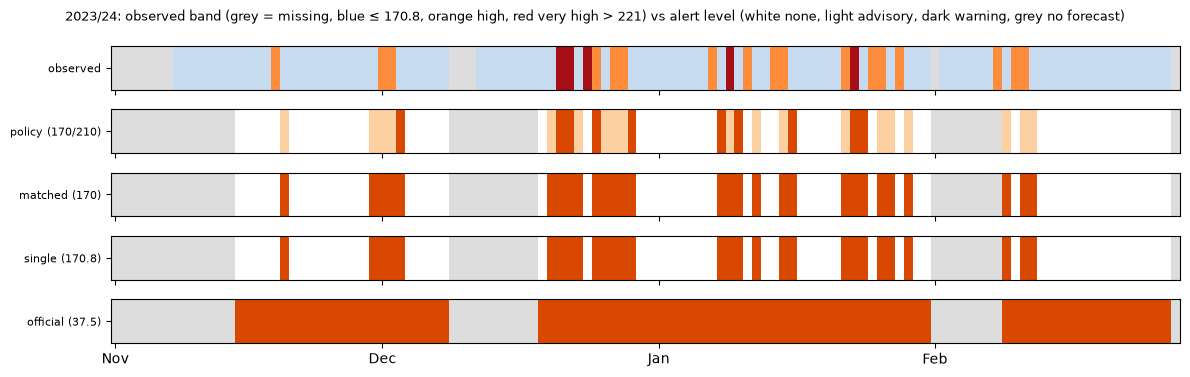

In [5]:
w_label = "2023/24"
days = pd.date_range(f"{w_label[:4]}-11-01", f"{int(w_label[:4]) + 1}-02-28", freq="D")
days = days[days.month.isin(cfg["smog_months"])]
obs = y.reindex(days)
band = np.select([obs.isna(), obs > very_high, obs > W["high"]], [0, 3, 2], 1)
fc = f_best.reindex(days)
def strip(levels):
    return np.where(fc.isna(), 0, levels.reindex(days).fillna(0).to_numpy() + 1)
rows = np.vstack([band, strip(lev), strip(lev_matched), strip(lev_single), strip(lev_off)])
fig, axes = plt.subplots(5, 1, figsize=(12, 3.8), sharex=True)
cm_obs = ListedColormap(["#DDDDDD", "#C6DBEF", "#FD8D3C", "#A50F15"])
cm_lev = ListedColormap(["#DDDDDD", "#FFFFFF", "#FDD0A2", "#D94801"])
labels = ["observed", f"policy ({policy['t1']:g}/{policy['t2']:g})", f"single ({W['high']:g})", f"official ({official:g})"]
labels.insert(2, f"matched ({thr_matched:.0f})")
for ax, r, cm, lab in zip(axes, rows, [cm_obs, cm_lev, cm_lev, cm_lev, cm_lev], labels):
    ax.imshow(r[None, :], aspect="auto", cmap=cm, vmin=0, vmax=3, interpolation="nearest")
    ax.set_yticks([0], [lab], fontsize=8)
ticks = [i for i, d in enumerate(days) if d.day == 1]
axes[-1].set_xticks(ticks, [days[i].strftime("%b") for i in ticks])
fig.suptitle(f"{w_label}: observed band (grey = missing, blue ≤ {W['high']:g}, orange high, red very high > {very_high:.0f}) "
             f"vs alert level (white none, light advisory, dark warning, grey no forecast)", fontsize=9)
fig.tight_layout(); plt.show()

## 5 · Sealed test cell
Runs **once, on 23 November**: refits the chosen model on all rows up to the end of validation (`fit_final_and_predict` / `fit_final_and_predict_lstm`), predicts the test winter and applies the frozen policy. Keep `RUN_TEST = False` until then.

In [6]:
RUN_TEST = False   # set True ONLY on 23 November, once, after the pre-test tag

if RUN_TEST:
    import re
    from uaq import features, sequence
    frozen = json.loads((res_dir / "warning_policy.json").read_text(encoding="utf-8"))
    pol = {k: frozen[k] for k in ("input", "t1", "t2")}
    sel = json.loads((res_dir / "forecast_selected.json").read_text(encoding="utf-8"))
    m = re.fullmatch(r"max\((.+), today\)", pol["input"])
    model_name = m.group(1) if m else pol["input"]
    model_name = model_name if "(" in model_name else f"{model_name} (weather)"
    family = model_name.split()[0]
    if family in ("mlp", "hgb"):
        cols = features.feature_columns(feat, weather=True, drop=cfg["features"]["drop_columns"])
        cands = models.mlp_candidates(cfg) if family == "mlp" else models.hgb_candidates(cfg)
        tp = models.fit_final_and_predict(feat, cols, cands[sel["chosen"][model_name]["config"]], cfg)
    else:
        cols = sequence.sequence_columns(feat, cfg, weather=True)
        cand = sequence.lstm_candidates(cfg, cols)[sel["lstm"]["chosen"][model_name]["config"]]
        tp = sequence.fit_final_and_predict_lstm(feat, cols, sel["lstm"]["history_days"], cand, cfg)
    test_preds = tp.set_index("target_date")[["pred"]].rename(columns={"pred": f"pred_{model_name}"})
    test_days, test_card = wp.evaluate_on_test(pol, test_preds, feat, cfg, frozen["very_high"])
    _, single_test = wp.single_threshold_rule(test_days["forecast"], test_days["y"], cfg, frozen["very_high"])
    _, matched_test = wp.single_threshold_rule(test_days["forecast"], test_days["y"], cfg, frozen["very_high"],
                                               threshold=frozen["matched_single_threshold"])
    display(pd.DataFrame({"policy": test_card, "single threshold, matched (validation) threshold": matched_test,
                          "single threshold 170.8": single_test}).T)
else:
    print("Test winter sealed until 23 November (RUN_TEST = False).")

Test winter sealed until 23 November (RUN_TEST = False).


## 6 · Save

In [7]:
def plain(d):
    return {k: (v.item() if hasattr(v, "item") else v) for k, v in d.items()}

summary = {
    "run_date": pd.Timestamp.now().strftime("%Y-%m-%d"),
    "input": policy["input"], "t1": policy["t1"], "t2": policy["t2"],
    "high": W["high"], "very_high": very_high, "very_high_quantile": W["very_high_quantile"],
    "rules": {"max_warning_days_per_winter": W["max_warning_days_per_winter"],
              "max_consecutive_warnings": W["max_consecutive_warnings"],
              "fatigue": "after max_consecutive level-2 days in a row (calendar days), the next day is downgraded to level 1",
              "threshold_grid": W["threshold_grid"], "inputs": W["inputs"],
              "objective": "severity-weighted recall: high day 1 if alerted at any level; very-high day 2 at level 2, 1 at level 1",
              "ties": "fewer alerts, then config input order, then lower t1, t2",
              "budget": "in each validation winter: level-2 days <= max_warning_days_per_winter and alert days (any level) "
                        "<= max_alert_days_per_winter",
              "max_warning_days_per_winter_value": W["max_warning_days_per_winter"],
              "max_alert_days_per_winter": W["max_alert_days_per_winter"]},
    "revision": "pre-test-v2: total alert budget added after the first validation run (advisories were unbudgeted, so t1 "
                "went to the grid floor and the policy alerted on 158 of 219 days); test winter still sealed",
    "matched_single_threshold": thr_matched,
    "validation": {"policy": plain(card), "single_threshold_matched": plain(card_matched),
                   "single_threshold": plain(card_single), "official_line": plain(card_off)},
    "top10": res.head(10).to_dict(orient="records"),
}
(res_dir / "warning_policy.json").write_text(json.dumps(summary, indent=2, default=float), encoding="utf-8")

val = pd.DataFrame({"winter": winter, "y": y,
                    "band": np.select([y > very_high, y > W["high"]], ["very high", "high"], "below high"),
                    "forecast": f_best.reindex(y.index), "level_policy": lev.reindex(y.index).fillna(0).astype(int),
                    "level_single_matched": lev_matched.reindex(y.index).fillna(0).astype(int),
                    "level_single": lev_single.reindex(y.index).fillna(0).astype(int),
                    "level_official": lev_off.reindex(y.index).fillna(0).astype(int)}).rename_axis("target_date")
val.to_csv(res_dir / "warning_validation.csv")
for f in ("warning_policy.json", "warning_validation.csv"):
    print("Saved", res_dir / f)

Saved /Users/user/Desktop/neural/outputs/results/warning_policy.json
Saved /Users/user/Desktop/neural/outputs/results/warning_validation.csv
